# Evaluate TorchXRayVision models in PadChest dataset

Evaluate 2 models available in TorchXRayVision Library:

1. resnet50: Trained in all datasets, Resolution = 512 x 512

2. densenet121: Trained in PadChest, Resolution = 224 x 224

In [2]:
import os
import pandas as pd
import numpy as np
import torch
import tqdm
import sklearn
from sklearn import metrics
import torchvision
import torchxrayvision as xrv
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from typing import Dict, List
from skimage.io import imread
import random

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'Device: {DEVICE}')
import train_utils

Device: cuda


# Load model

### resnet50

In [6]:
model_resnet = xrv.models.ResNet(weights="resnet50-res512-all")
model_resnet.to(DEVICE)

XRV-ResNet-resnet50-res512-all

### densenet121

In [7]:
model_densenet = xrv.models.DenseNet(weights="densenet121-res224-pc")
model_densenet.to(DEVICE)

XRV-DenseNet121-densenet121-res224-pc

## Create PC dataset

In [8]:
class Dataset:
    """The datasets in this library aim to fit a simple interface where the
    imgpath and csvpath are specified. Some datasets require more than one
    metadata file and for some the metadata files are packaged in the library
    so only the imgpath needs to be specified.
    """
    def __init__(self):
        pass

    pathologies: List[str]

    labels: np.ndarray

    csv: pd.DataFrame

    def totals(self) -> Dict[str, Dict[str, int]]:
        """Compute counts of pathologies.

        Returns: A dict containing pathology name -> (label->value)
        """
        counts = [dict(collections.Counter(items[~np.isnan(items)]).most_common()) for items in self.labels.T]
        return dict(zip(self.pathologies, counts))

    def __repr__(self) -> str:
        """Returns the name and a description of the dataset such as:

        .. code-block:: python

            CheX_Dataset num_samples=191010 views=['PA', 'AP']

        If in a jupyter notebook it will also print the counts of the
        pathology counts returned by .totals()

        .. code-block:: python

            {'Atelectasis': {0.0: 17621, 1.0: 29718},
             'Cardiomegaly': {0.0: 22645, 1.0: 23384},
             'Consolidation': {0.0: 30463, 1.0: 12982},
             ...}

        """
        if xrv.utils.in_notebook():
            pprint.pprint(self.totals())
        return self.string()

    def check_paths_exist(self):
        if not os.path.isdir(self.imgpath):
            raise Exception("imgpath must be a directory")
        if not os.path.isfile(self.csvpath):
            raise Exception("csvpath must be a file")

    def limit_to_selected_views(self, views):
        """This function is called by subclasses to filter the
        images by view based on the values in .csv['view']
        """
        if type(views) is not list:
            views = [views]
        if '*' in views:
            # if you have the wildcard, the rest are irrelevant
            views = ["*"]
        self.views = views

        # missing data is unknown
        self.csv.view.fillna("UNKNOWN", inplace=True)

        if "*" not in views:
            self.csv = self.csv[self.csv["view"].isin(self.views)]  # Select the view

In [9]:
def normalize(img, maxval, reshape=False):
    """Scales images to be roughly [-1024 1024].

    Call xrv.utils.normalize moving forward.
    """
    return xrv.utils.normalize(img, maxval, reshape)


def apply_transforms(sample, transform, seed=None) -> Dict:
    """Applies transforms to the image and masks.
    The seeds are set so that the transforms that are applied
    to the image are the same that are applied to each mask.
    This way data augmentation will work for segmentation or 
    other tasks which use masks information.
    """

    if seed is None:
        MAX_RAND_VAL = 2147483647
        seed = np.random.randint(MAX_RAND_VAL)

    if transform is not None:
        random.seed(seed)
        torch.random.manual_seed(seed)
        sample["img"] = transform(sample["img"])

        if "pathology_masks" in sample:
            for i in sample["pathology_masks"].keys():
                random.seed(seed)
                torch.random.manual_seed(seed)
                sample["pathology_masks"][i] = transform(sample["pathology_masks"][i])

        if "semantic_masks" in sample:
            for i in sample["semantic_masks"].keys():
                random.seed(seed)
                torch.random.manual_seed(seed)
                sample["semantic_masks"][i] = transform(sample["semantic_masks"][i])

    return sample

In [29]:
class PC_Dataset(Dataset):

    def __init__(self,
                 imgpath,
                 csvpath,
                 avail_imgID,
                 views=["PA"],
                 transform=None,
                 data_aug=None,
                 flat_dir=True,
                 seed=0,
                 unique_patients=True
                 ):

        super(PC_Dataset, self).__init__()
        np.random.seed(seed)  # Reset the seed so all runs are the same.

        self.pathologies = ["Atelectasis", "Consolidation", "Infiltration",
                            "Pneumothorax", "Edema", "Emphysema", "Fibrosis",
                            "Effusion", "Pneumonia", "Pleural_Thickening",
                            "Cardiomegaly", "Nodule", "Mass", "Hernia", "Fracture",
                            "Granuloma", "Flattened Diaphragm", "Bronchiectasis",
                            "Aortic Elongation", "Scoliosis",
                            "Hilar Enlargement", "Tuberculosis",
                            "Air Trapping", "Costophrenic Angle Blunting", "Aortic Atheromatosis",
                            "Hemidiaphragm Elevation",
                            "Support Devices", "Tube'"]  # the Tube' is intentional

        self.pathologies = sorted(self.pathologies)

        mapping = dict()

        mapping["Infiltration"] = ["infiltrates",
                                   "interstitial pattern",
                                   "ground glass pattern",
                                   "reticular interstitial pattern",
                                   "reticulonodular interstitial pattern",
                                   "alveolar pattern",
                                   "consolidation",
                                   "air bronchogram"]
        mapping["Pleural_Thickening"] = ["pleural thickening"]
        mapping["Consolidation"] = ["air bronchogram"]
        mapping["Hilar Enlargement"] = ["adenopathy",
                                        "pulmonary artery enlargement"]
        mapping["Support Devices"] = ["device",
                                      "pacemaker"]
        mapping["Tube'"] = ["stent'"]  # the ' is to select findings which end in that word

        self.imgpath = imgpath
        self.transform = transform
        self.data_aug = data_aug
        self.flat_dir = flat_dir
        self.csvpath = csvpath
        
        self.csv = pd.read_csv(self.csvpath, low_memory=False)

        # Standardize view names
        self.csv.loc[self.csv["Projection"].isin(["AP_horizontal"]), "Projection"] = "AP Supine"

        self.csv["view"] = self.csv['Projection']
        self.limit_to_selected_views(views)

        # Remove null stuff
        self.csv = self.csv[~self.csv["Labels"].isnull()]
        
        #----------------ADDED------------------
        # Filter by available image files
        self.csv = self.csv[self.csv["ImageID"].isin(avail_imgID)]
        
        # Exclude the labels:
        self.csv = self.csv[~self.csv["Labels"].str.contains('exclude')]
        self.csv = self.csv[~self.csv["Labels"].str.contains('suboptimal study')]
        #----------------ADDED------------------

        if unique_patients:
            self.csv = self.csv.groupby("PatientID").first().reset_index()

        # Filter out age < 10 (paper published 2019)
        self.csv = self.csv[(2019 - self.csv.PatientBirth > 10)]

        # Get our classes.
        labels = []
        for pathology in self.pathologies:
            mask = self.csv["Labels"].str.contains(pathology.lower())
            if pathology in mapping:
                for syn in mapping[pathology]:
                    #print("mapping", syn)
                    mask |= self.csv["Labels"].str.contains(syn.lower())
            labels.append(mask.values)
        self.labels = np.asarray(labels).T
        self.labels = self.labels.astype(np.float32)

        self.pathologies[self.pathologies.index("Tube'")] = "Tube"

        # add consistent csv values

        # offset_day_int
        dt = pd.to_datetime(self.csv["StudyDate_DICOM"], format="%Y%m%d")
        self.csv["offset_day_int"] = dt.astype(np.int64) // 10**9 // 86400

        # patientid
        self.csv["patientid"] = self.csv["PatientID"].astype(str)

        # age
        self.csv['age_years'] = (2017 - self.csv['PatientBirth'])

        # sex
        self.csv['sex_male'] = self.csv['PatientSex_DICOM'] == 'M'
        self.csv['sex_female'] = self.csv['PatientSex_DICOM'] == 'F'

    def string(self):
        return self.__class__.__name__ + " num_samples={} views={} data_aug={}".format(len(self), self.views, self.data_aug)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        sample = {}
        sample["idx"] = idx
        sample["lab"] = self.labels[idx]

        imgid = self.csv['ImageID'].iloc[idx]
        img_path = os.path.join(self.imgpath, imgid)
        img = imread(img_path)

        sample["img"] = normalize(img, maxval=65535, reshape=True)

        sample = apply_transforms(sample, self.transform)
        sample = apply_transforms(sample, self.data_aug)

        return sample

### Filter by available image IDs

In [11]:
imageIDs_available = os.path.join("C:/Users/maria/OneDrive/Documentos/Escritorio/CodeChestXRay/TrainXray/normal_classification/normal_classify_training/Resources/txt_files/PC512_Full_PA_filtered_dataset/imageIDs", "PadChest_512_PA_manually_filtered_87946.txt")
with open(imageIDs_available, "r") as f:
    avail_ID = [line.strip() for line in f.readlines()]

# Evaluate the model: Resnet 50

In [12]:
model_resnet.pathologies

['Atelectasis',
 'Consolidation',
 'Infiltration',
 'Pneumothorax',
 'Edema',
 'Emphysema',
 'Fibrosis',
 'Effusion',
 'Pneumonia',
 'Pleural_Thickening',
 'Cardiomegaly',
 'Nodule',
 'Mass',
 'Hernia',
 'Lung Lesion',
 'Fracture',
 'Lung Opacity',
 'Enlarged Cardiomediastinum']

### Load the dataset

In [30]:
d_pc = PC_Dataset(imgpath = "C:/Users/maria/OneDrive/Documentos/Escritorio/CodeChestXRay/TrainXray/Data/PadChest512_PA_Manually_Filtered",
                 csvpath = "C:/Users/maria/OneDrive/Documentos/Escritorio/CodeChestXRay/TrainXray/Data/PADCHEST_chest_x_ray_images_labels_160K_01.02.19.csv" ,
                 avail_imgID = avail_ID )
xrv.datasets.relabel_dataset(xrv.datasets.default_pathologies, d_pc)

{'Aortic Elongation', 'Scoliosis', 'Bronchiectasis', 'Granuloma', 'Air Trapping', 'Tube', 'Costophrenic Angle Blunting', 'Support Devices', 'Aortic Atheromatosis', 'Hilar Enlargement', 'Hemidiaphragm Elevation', 'Flattened Diaphragm', 'Tuberculosis'} will be dropped
Lung Lesion doesn't exist. Adding nans instead.
Lung Opacity doesn't exist. Adding nans instead.
Enlarged Cardiomediastinum doesn't exist. Adding nans instead.


In [11]:
len(d_pc)

59506

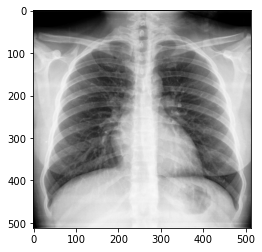

In [24]:
sample = d_pc[10]
plt.imshow(sample["img"][0], cmap="Greys_r");

## Using optimal threshold: op_threshs

In [12]:
print("Optimal thresholds for each pathology:\n", model_resnet.op_threshs)
print("\nApply sigmoid:\n", model_resnet.apply_sigmoid)

Optimal thresholds for each pathology:
 tensor([0.5157, 0.5044, 0.5379, 0.5072, 0.5025, 0.5035, 0.5038, 0.5186, 0.5078,
        0.5072, 0.5056, 0.5107, 0.5054, 0.5021,    nan, 0.5081, 0.5139,    nan],
       device='cuda:0')

Apply sigmoid:
 False


In [13]:
outs = []
labs = []
with torch.no_grad():
    np.random.seed(0)
    for i in tqdm.tqdm(range(len(d_pc))):
        sample = d_pc[i]
        labs.append(sample["lab"])
        image = torch.from_numpy(sample["img"]).unsqueeze(0)
        if torch.cuda.is_available():
            image = image.cuda()
        out = model_resnet(image).cpu()
        outs.append(out.detach().numpy()[0])

100%|████████████████████████████████████████████████████████████████████████████| 59506/59506 [49:49<00:00, 19.91it/s]


In [25]:
results = []

def calculate_metrics(index):
    result = {}
    result["Pathology"] = model_resnet.pathologies[index]
    if len(np.unique(np.asarray(labs)[:, index])) > 1:
        labels = np.asarray(labs)[:, index].astype(bool)
        preds = np.asarray(outs)[:, index]
        result["AUC"] = sklearn.metrics.roc_auc_score(labels, preds)
        result["Acc"] = sklearn.metrics.accuracy_score(labels, preds > 0.5)
        result["Prec"] = sklearn.metrics.precision_score(labels, preds > 0.5)
        result["Recall"] = sklearn.metrics.recall_score(labels, preds > 0.5)
        result["F1"] = sklearn.metrics.f1_score(labels, preds > 0.5)
    return result

# Scroll through elements from 0 to 13
results = [calculate_metrics(i) for i in range(14)]

# Calculate metrics for element 15 directly
results.append(calculate_metrics(15))

pd.DataFrame(results)


,Pathology,AUC,Acc,Prec,Recall,F1
0,Atelectasis,0.798683,0.960475,0.464286,0.027754,0.052377
1,Consolidation,0.890673,0.992068,0.296296,0.017354,0.032787
2,Infiltration,0.823094,0.931570,0.624378,0.060163,0.109751
3,Pneumothorax,0.841412,0.998387,0.000000,0.000000,0.000000
4,Edema,0.968303,0.998202,0.000000,0.000000,0.000000
5,Emphysema,0.851760,0.990925,0.222222,0.003738,0.007353
6,Fibrosis,0.955527,0.994404,0.513636,0.333333,0.404293
7,Effusion,0.948241,0.979565,0.825540,0.290875,0.430178
8,Pneumonia,0.777661,0.968726,0.500000,0.029017,0.054850
9,Pleural_Thickening,0.850311,0.966827,0.531722,0.088221,0.151333


## Using ppv80 threshold: ppv80_thres

In [37]:
model_resnet.op_threshs = torch.tensor([0.690908, 0.720028, 0.7303882, 0.7235838, 0.6787441, 0.7304924, 0.73105824, 0.6839408, 0.7241559, 0.7219969, 0.6346738, 0.72764945, 0.7285066, 0.5735704, np.nan, 0.69684714, 0.7135549, np.nan])
model_resnet.to(DEVICE)

XRV-ResNet-resnet50-res512-all

In [38]:
print(model_resnet.op_threshs)

tensor([0.6909, 0.7200, 0.7304, 0.7236, 0.6787, 0.7305, 0.7311, 0.6839, 0.7242,
        0.7220, 0.6347, 0.7276, 0.7285, 0.5736,    nan, 0.6968, 0.7136,    nan],
       device='cuda:0')


In [39]:
outs = []
labs = []
with torch.no_grad():
    np.random.seed(0)
    for i in tqdm.tqdm(range(len(d_pc))):
        sample = d_pc[i]
        labs.append(sample["lab"])
        image = torch.from_numpy(sample["img"]).unsqueeze(0)
        if torch.cuda.is_available():
            image = image.cuda()
        out = model_resnet(image).cpu()
        outs.append(out.detach().numpy()[0])

100%|████████████████████████████████████████████████████████████████████████████| 59506/59506 [49:20<00:00, 20.10it/s]


In [41]:
results = []

def calculate_metrics(index):
    result = {}
    result["Pathology"] = model_resnet.pathologies[index]
    if len(np.unique(np.asarray(labs)[:, index])) > 1:
        labels = np.asarray(labs)[:, index].astype(bool)
        preds = np.asarray(outs)[:, index]
        result["AUC"] = sklearn.metrics.roc_auc_score(labels, preds)
        result["Acc"] = sklearn.metrics.accuracy_score(labels, preds > 0.5)
        result["Prec"] = sklearn.metrics.precision_score(labels, preds > 0.5)
        result["Recall"] = sklearn.metrics.recall_score(labels, preds > 0.5)
        result["F1"] = sklearn.metrics.f1_score(labels, preds > 0.5)
    return result

# Scroll through elements from 0 to 13
results = [calculate_metrics(i) for i in range(14)]

# Calculate metrics for element 15 directly
results.append(calculate_metrics(15))

pd.DataFrame(results)


,Pathology,AUC,Acc,Prec,Recall,F1
0,Atelectasis,0.798683,0.960777,0.642857,0.007686,0.015190
1,Consolidation,0.890673,0.992270,0.571429,0.008677,0.017094
2,Infiltration,0.823094,0.930024,0.554054,0.009827,0.019312
3,Pneumothorax,0.841412,0.998404,0.000000,0.000000,0.000000
4,Edema,0.968303,0.998202,0.000000,0.000000,0.000000
5,Emphysema,0.851760,0.990993,0.333333,0.001869,0.003717
6,Fibrosis,0.955527,0.994958,0.705263,0.197640,0.308756
7,Effusion,0.948241,0.977280,0.881757,0.165399,0.278549
8,Pneumonia,0.777661,0.968928,0.625000,0.016120,0.031430
9,Pleural_Thickening,0.850311,0.966676,0.561224,0.027569,0.052556


# Evaluate the model: Densenet 121

In [42]:
print("Optimal thresholds for each pathology:\n", model_densenet.op_threshs)
print("\nApply sigmoid:\n", model_densenet.apply_sigmoid)

Optimal thresholds for each pathology:
 tensor([0.0310, 0.0133, 0.0814, 0.0013, 0.0026, 0.0036, 0.0023, 0.0554, 0.0444,
        0.0428, 0.0433, 0.0376, 0.0057, 0.0092,    nan, 0.0265,    nan,    nan],
       device='cuda:0')

Apply sigmoid:
 False


In [64]:
d_pc = PC_Dataset(imgpath = "C:/Users/maria/OneDrive/Documentos/Escritorio/CodeChestXRay/TrainXray/Data/PadChest512_PA_Manually_Filtered",
                 csvpath = "C:/Users/maria/OneDrive/Documentos/Escritorio/CodeChestXRay/TrainXray/Data/PADCHEST_chest_x_ray_images_labels_160K_01.02.19.csv" ,
                 avail_imgID = avail_ID)
xrv.datasets.relabel_dataset(xrv.datasets.default_pathologies, d_pc)

{'Granuloma', 'Scoliosis', 'Flattened Diaphragm', 'Hilar Enlargement', 'Bronchiectasis', 'Air Trapping', 'Tube', 'Tuberculosis', 'Hemidiaphragm Elevation', 'Aortic Elongation', 'Support Devices', 'Costophrenic Angle Blunting', 'Aortic Atheromatosis'} will be dropped
Lung Lesion doesn't exist. Adding nans instead.
Lung Opacity doesn't exist. Adding nans instead.
Enlarged Cardiomediastinum doesn't exist. Adding nans instead.


### Check if the model aligns with the dataset

In [53]:
dict(zip(model_densenet.pathologies,d_pc.pathologies))

{'Atelectasis': 'Atelectasis',
 'Consolidation': 'Consolidation',
 'Infiltration': 'Infiltration',
 'Pneumothorax': 'Pneumothorax',
 'Edema': 'Edema',
 'Emphysema': 'Emphysema',
 'Fibrosis': 'Fibrosis',
 'Effusion': 'Effusion',
 'Pneumonia': 'Pneumonia',
 'Pleural_Thickening': 'Pleural_Thickening',
 'Cardiomegaly': 'Cardiomegaly',
 'Nodule': 'Nodule',
 'Mass': 'Mass',
 'Hernia': 'Hernia',
 '': 'Enlarged Cardiomediastinum',
 'Fracture': 'Fracture'}

In [65]:
outs = []
labs = []
with torch.no_grad():
    np.random.seed(0)
    for i in tqdm.tqdm(range(len(d_pc))):
        sample = d_pc[i]
        labs.append(sample["lab"])
        image = torch.from_numpy(sample["img"]).unsqueeze(0)
        if torch.cuda.is_available():
            image = image.cuda()
        out = model_densenet(image).cpu()
        outs.append(out.detach().numpy()[0])

  0%|                                                                              | 1/59506 [00:00<2:19:12,  7.12it/s]

100%|██████████████████████████████████████████████████████████████████████████| 59506/59506 [1:18:36<00:00, 12.62it/s]


In [67]:
results = []

def calculate_metrics(index):
    result = {}
    result["Pathology"] = model_densenet.pathologies[index]
    if len(np.unique(np.asarray(labs)[:, index])) > 1:
        labels = np.asarray(labs)[:, index].astype(bool)
        preds = np.asarray(outs)[:, index]
        result["AUC"] = sklearn.metrics.roc_auc_score(labels, preds)
        result["Acc"] = sklearn.metrics.accuracy_score(labels, preds > 0.5)
        result["Prec"] = sklearn.metrics.precision_score(labels, preds > 0.5)
        result["Recall"] = sklearn.metrics.recall_score(labels, preds > 0.5)
        result["F1"] = sklearn.metrics.f1_score(labels, preds > 0.5)
    return result

# Scroll through elements from 0 to 13
results = [calculate_metrics(i) for i in range(14)]

# Calculate metrics for element 15 directly
results.append(calculate_metrics(15))

pd.DataFrame(results)

,Pathology,AUC,Acc,Prec,Recall,F1
0,Atelectasis,0.800661,0.668084,0.087758,0.791204,0.157991
1,Consolidation,0.914145,0.856888,0.044246,0.848156,0.084104
2,Infiltration,0.848151,0.738615,0.184219,0.795781,0.299180
3,Pneumothorax,0.908876,0.703122,0.004958,0.936170,0.009864
4,Edema,0.977144,0.918596,0.020449,0.943925,0.040032
5,Emphysema,0.893527,0.815666,0.038727,0.818692,0.073955
6,Fibrosis,0.960223,0.875592,0.040344,0.914454,0.077278
7,Effusion,0.954039,0.905539,0.202589,0.872624,0.328836
8,Pneumonia,0.865767,0.786576,0.106741,0.790435,0.188083
9,Pleural_Thickening,0.824416,0.731489,0.088081,0.749373,0.157634


## Calibrate the model: Resnet50

In [166]:
import train_utils
test_loader = torch.utils.data.DataLoader(d_pc,
                                           batch_size=32,
                                           shuffle=False)
outputs = train_utils.valid_test_epoch("test", 0, model_resnet, "cuda", test_loader, torch.nn.BCEWithLogitsLoss(), limit=99999999)

Epoch 1 - test - Loss = 10.5377: 100%|█████████████████████████████████████████████| 1860/1860 [33:48<00:00,  1.09s/it]


Epoch 1 - test - Avg AUC = 0.8729


In [212]:
all_threshs = []
all_ppv80 = []

for i, patho in enumerate(d_pc.pathologies):
    opt_thres = np.nan
    ppv80_thres = np.nan
    
    if (len(outputs[3][i]) > 0) and (len(np.unique(outputs[3][i])) == 2):
        
        #sigmoid
        all_outputs = 1.0/(1.0 + np.exp(-outputs[2][i]))
        
        fpr, tpr, thres = sklearn.metrics.roc_curve(outputs[3][i], all_outputs)
        pente = tpr - fpr
        opt_thres = thres[np.argmax(pente)]
        
        ppv, recall, thres = sklearn.metrics.precision_recall_curve(outputs[3][i], all_outputs)
        ppv80_thres_idx = np.where(ppv > 0.8)[0][0]
        ppv80_thres = thres[ppv80_thres_idx-1]
        
        all_threshs.append(opt_thres)
        all_ppv80.append(ppv80_thres)
        print(f"Pathology:{patho}\n optmimal threshold:{opt_thres}\n ppv80_thres:{ppv80_thres}\n")

Pathology:Atelectasis
 optmimal threshold:0.5127841830253601
 ppv80_thres:0.6863909363746643

Pathology:Consolidation
 optmimal threshold:0.5037833452224731
 ppv80_thres:0.7141665816307068

Pathology:Infiltration
 optmimal threshold:0.532951295375824
 ppv80_thres:0.7302606105804443

Pathology:Pneumothorax
 optmimal threshold:0.5019515752792358
 ppv80_thres:0.690041720867157

Pathology:Edema
 optmimal threshold:0.5010840892791748
 ppv80_thres:0.5991843938827515

Pathology:Emphysema
 optmimal threshold:0.5031761527061462
 ppv80_thres:0.7150498628616333

Pathology:Fibrosis
 optmimal threshold:0.5115091800689697
 ppv80_thres:0.7237238883972168

Pathology:Effusion
 optmimal threshold:0.5136830806732178
 ppv80_thres:0.6095097661018372

Pathology:Pneumonia
 optmimal threshold:0.5026437044143677
 ppv80_thres:0.7273339033126831

Pathology:Pleural_Thickening
 optmimal threshold:0.5080977082252502
 ppv80_thres:0.7249652743339539

Pathology:Cardiomegaly
 optmimal threshold:0.5045619010925293
 ppv8

In [206]:
all_threshs

[0.5127842,
 0.50378335,
 0.5329513,
 0.5019516,
 0.5010841,
 0.50317615,
 0.5115092,
 0.5136831,
 0.5026437,
 0.5080977,
 0.5045619,
 0.50960636,
 0.5044478,
 0.50306815,
 0.51025593]

In [207]:
all_ppv80

[0.68639094,
 0.7141666,
 0.7302606,
 0.6900417,
 0.5991844,
 0.71504986,
 0.7237239,
 0.60950977,
 0.7273339,
 0.7249653,
 0.5783999,
 0.68571204,
 0.7288465,
 0.5545753,
 0.6716706]